In [1]:
import sys

print("Colab está funcionando")
print("Versión de Python:", sys.version)

!java -version

Colab está funcionando
Versión de Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [2]:
%pip install -q pyspark==3.5.3 kafka-python pandas matplotlib

In [3]:
%pip install -q "pyspark==4.0.1" kafka-python pandas matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [4]:
import pyspark, sys
print("Python:", sys.version.split()[0])
print("PySpark:", pyspark.__version__)

Python: 3.13.18
PySpark: 4.0.1


In [5]:
import os
os.environ["PYSPARK_SUBMIT_ARGS"] = (
    "--packages org.apache.spark:spark-sql-kafka-0-10_2.13:4.0.1 pyspark-shell"
)

from pyspark.sql import SparkSession
spark = (SparkSession.builder
         .appName("Tarea3_BigData")
         .master("local[*]")
         .config("spark.ui.port", "4040")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark:", spark.version)
print("App ID:", spark.sparkContext.applicationId)

Spark: 4.0.1
App ID: local-1793323566880


In [6]:
from google.colab import files
files.upload()   # sube archive.zip

Saving archive.zip to archive.zip
Saving bank+marketing.zip to bank+marketing.zip


{'archive.zip': b'PK\x03\x04-\x00\x00\x00\x08\x00`}\'R\xbfz@\x1d\xff\xff\xff\xff\xff\xff\xff\xff\x18\x00\x14\x00bank-additional-full.csv\x01\x00\x10\x00\xc7gX\x00\x00\x00\x00\x00\xda\x19\x06\x00\x00\x00\x00\x00\xd4}\xdb\x92\x1cG\x8e\xe5{\x7f\x86\xdeG\x16\x00\xdc=",?f\x8d\x12\xabG\xdc\x15)\x1a\x8b\x9cY\xfd\xfd\xa6gVwU\\\xdc\x01\x1cx\xd6p_\xd4\xc5\x96\x98y\n\x8e\xfb\xf5\x97\x0f\xff\xf9\xf4\xcb\xe5\x97\xff\xfd\xd7o\xd7\x7f~\xfe\xf0\xed\xd3\xf7\x0f\x7f^\x7fz\xfa\xf8\xe3\xf7\x0f\xdf?\xfd\xf5\xe5\xfa\xf3\xc7\xa7\x7f~\xf8\xf1\xe7\xf7\xebO\x7f\xfc\xf5\xe3\xf9\xd3\x97\xff\xbc\xfe\xf4\xe7_\x1f\xea\xbf\xfa\xfd\xaf/\xdf?\xfc^\xff\xd5\xe7\xebO\x7f\xd4\xff\xf8\xc3\xdf\xff\xeb\xaf\x7f\xfe\xaf\xff~z\xfa?\xf5O?\xbe\xfd\xebS~\xff\xf0\xf9\xeb\x87O\xffY\x7f\xfcz\xfd\x8f\x9e\xeb\xff~{\xfa\xafO\xd7\x8f\xac?\xfe\xf5\xe3\xfb\xef\x7f}\xaeP\x9e>\x7f\xfd\xf5\xbf>|\xfb\xf5\xfa7\x9f\xee_\xf1\xfc\xeb\xd7o\x9f~\x7f\xfa\xf5\xd3\xc7\xff\xfb\xaf\xff\xe3\xfa\x8f\x7f\xbe\xfc\xf9\xe9\xc7\xb7O\xbf\xfd\xf5M>_\x7f\xfe\xf2\xe

In [7]:
!unzip -o archive.zip
!ls -lh *.csv
!head -2 bank-additional-full.csv

Archive:  archive.zip
  inflating: bank-additional-full.csv  
-rw-r--r-- 1 root root 5.6M Jan  7  2021 bank-additional-full.csv
"age";"job";"marital";"education";"default";"housing";"loan";"contact";"month";"day_of_week";"duration";"campaign";"pdays";"previous";"poutcome";"emp.var.rate";"cons.price.idx";"cons.conf.idx";"euribor3m";"nr.employed";"y"
56;"housemaid";"married";"basic.4y";"no";"no";"no";"telephone";"may";"mon";261;1;999;0;"nonexistent";1.1;93.994;-36.4;4.857;5191;"no"


In [8]:
import os
os.environ["PYSPARK_SUBMIT_ARGS"] = (
    "--packages org.apache.spark:spark-sql-kafka-0-10_2.13:4.0.1 pyspark-shell"
)

from pyspark.sql import SparkSession
spark = (SparkSession.builder
         .appName("Tarea3_BigData")
         .master("local[*]")
         .config("spark.ui.port", "4040")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark:", spark.version)
print("App ID:", spark.sparkContext.applicationId)

Spark: 4.0.1
App ID: local-1793323566880


Filas: 41188 | Columnas: 21
root
 |-- age: integer (nullable = true)
 |-- job: string (nullable = true)
 |-- marital: string (nullable = true)
 |-- education: string (nullable = true)
 |-- default: string (nullable = true)
 |-- housing: string (nullable = true)
 |-- loan: string (nullable = true)
 |-- contact: string (nullable = true)
 |-- month: string (nullable = true)
 |-- day_of_week: string (nullable = true)
 |-- duration: integer (nullable = true)
 |-- campaign: integer (nullable = true)
 |-- pdays: integer (nullable = true)
 |-- previous: integer (nullable = true)
 |-- poutcome: string (nullable = true)
 |-- emp_var_rate: double (nullable = true)
 |-- cons_price_idx: double (nullable = true)
 |-- cons_conf_idx: double (nullable = true)
 |-- euribor3m: double (nullable = true)
 |-- nr_employed: double (nullable = true)
 |-- y: string (nullable = true)

+---+---------+-------+-----------+-------+-------+----+---------+-----+-----------+--------+--------+-----+--------+-----------+

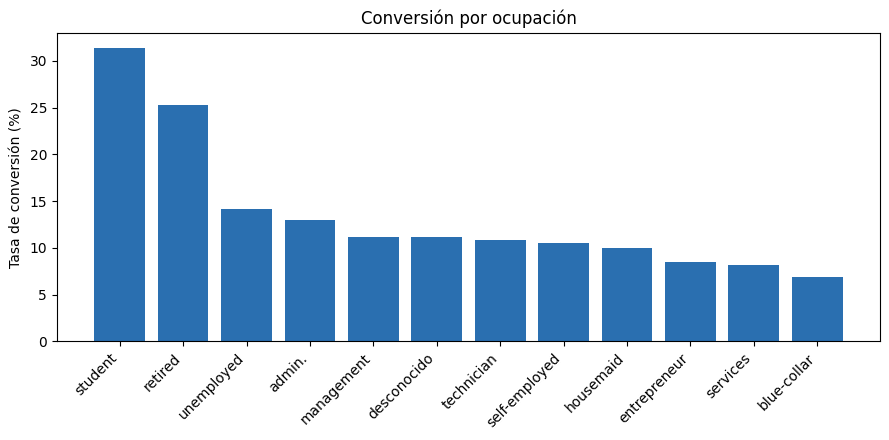

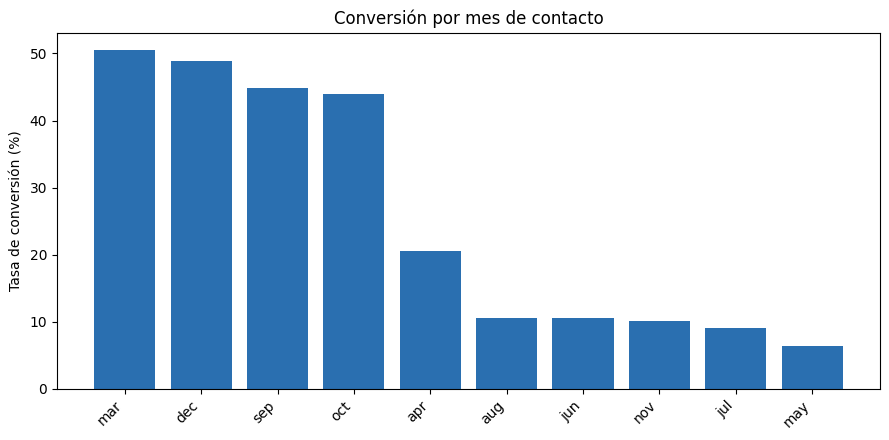

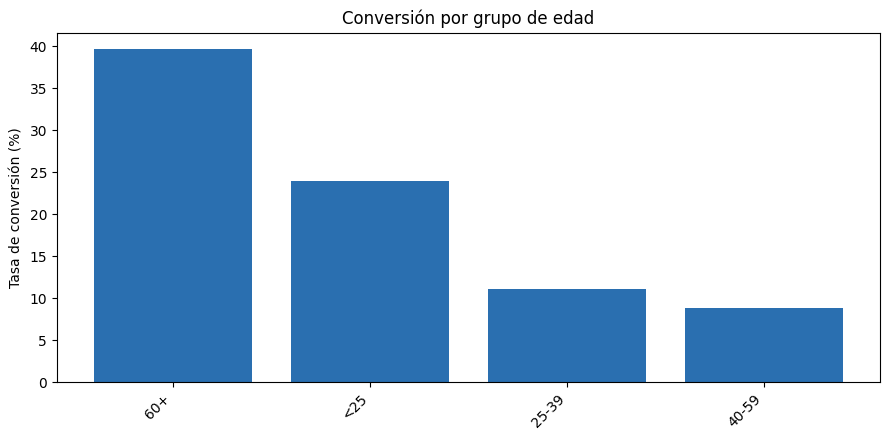

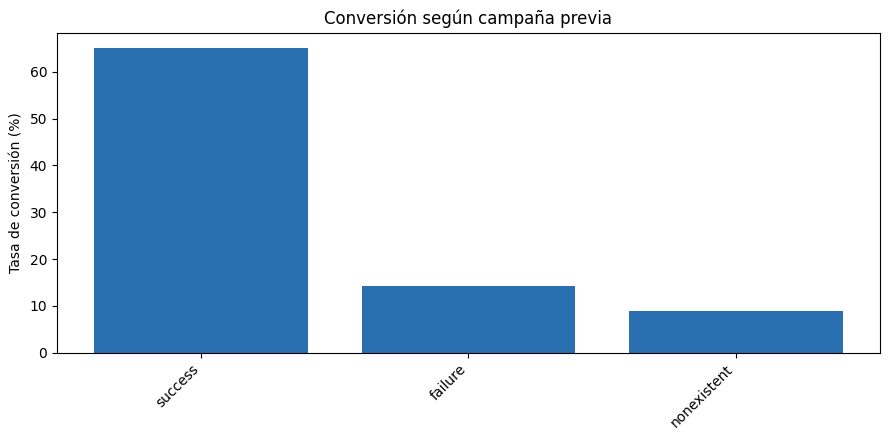

Batch terminado


In [9]:
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

df = (spark.read.option("header", True).option("sep", ";")
      .option("inferSchema", True).csv("bank-additional-full.csv"))

# Renombrar columnas con puntos antes de usarlas
for a, b in [("emp.var.rate","emp_var_rate"),("cons.price.idx","cons_price_idx"),
             ("cons.conf.idx","cons_conf_idx"),("nr.employed","nr_employed")]:
    df = df.withColumnRenamed(a, b)

print("Filas:", df.count(), "| Columnas:", len(df.columns))
df.printSchema()
df.show(5, False)

# --- Limpieza ---
df = df.dropDuplicates()
cat_cols = ["job","marital","education","default","housing","loan"]
for c in cat_cols:
    df = df.withColumn(c, F.when(F.col(c) == "unknown", None).otherwise(F.col(c)))

print("Nulos por columna categórica (antes de imputar):")
df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in cat_cols]).show()
df = df.fillna("desconocido", subset=cat_cols)

# --- Transformación ---
df = (df.withColumn("target", F.when(F.col("y") == "yes", 1).otherwise(0))
        .withColumn("grupo_edad", F.when(F.col("age") < 25, "<25")
                                   .when(F.col("age") < 40, "25-39")
                                   .when(F.col("age") < 60, "40-59").otherwise("60+"))
        .withColumn("duracion_min", F.round(F.col("duration")/60, 2)))
df.cache()

# --- EDA ---
df.describe("age","duration","campaign","euribor3m").show()
df.groupBy("y").count().show()

def tasa(col):
    return (df.groupBy(col)
              .agg(F.count("*").alias("total"),
                   F.round(F.avg("target")*100, 2).alias("tasa_conversion"))
              .orderBy(F.desc("tasa_conversion")))

for c in ["job","grupo_edad","marital","month","poutcome"]:
    print(f"\n=== {c} ===")
    tasa(c).show(20, False)

# --- Gráficos ---
graficos = [("job","Conversión por ocupación","g1_job.png"),
            ("month","Conversión por mes de contacto","g2_mes.png"),
            ("grupo_edad","Conversión por grupo de edad","g3_edad.png"),
            ("poutcome","Conversión según campaña previa","g4_poutcome.png")]

for col, titulo, arch in graficos:
    p = tasa(col).toPandas()
    plt.figure(figsize=(9, 4.5))
    plt.bar(p[col].astype(str), p["tasa_conversion"], color="#2a6fb0")
    plt.title(titulo)
    plt.ylabel("Tasa de conversión (%)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(arch, dpi=150)
    plt.show()

tasa("job").write.mode("overwrite").csv("salida_job", header=True)
print("Batch terminado")

In [10]:
import subprocess
from pathlib import Path

# Versión y ubicación utilizadas en esta adaptación a Colab.
kafka_dir = Path("kafka_2.12-3.7.1")
kafka_url = (
    "https://archive.apache.org/dist/kafka/3.7.1/"
    "kafka_2.12-3.7.1.tgz"
)

if not kafka_dir.exists():
    print("Descargando Kafka...")
    subprocess.run(
        ["curl", "-fL", "--retry", "3",
         kafka_url, "-o", "kafka_2.12-3.7.1.tgz"],
        check=True
    )

    print("Descomprimiendo Kafka...")
    subprocess.run(
        ["tar", "-xzf", "kafka_2.12-3.7.1.tgz"],
        check=True
    )

print("Comprobando la instalación...")
resultado = subprocess.run(
    [str(kafka_dir / "bin/kafka-topics.sh"), "--version"],
    check=True,
    capture_output=True,
    text=True
)

print(resultado.stdout)
print("Kafka descargado y comprobado. Todavía no hemos iniciado el servidor.")

Descargando Kafka...
Descomprimiendo Kafka...
Comprobando la instalación...
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
3.7.1

Kafka descargado y comprobado. Todavía no hemos iniciado el servidor.


In [11]:
from pathlib import Path
import subprocess
import time
import uuid

kafka_dir = Path("kafka_2.12-3.7.1")
config = kafka_dir / "config/kraft/server.properties"
storage = kafka_dir / "bin/kafka-storage.sh"
topics = kafka_dir / "bin/kafka-topics.sh"
log_file = open("kafka.log", "w")

# Preparar el almacenamiento solo si todavía no se ha inicializado
meta_file = Path("/tmp/kraft-combined-logs/meta.properties")
if not meta_file.exists():
    cluster_id = subprocess.check_output(
        [str(storage), "random-uuid"], text=True
    ).strip()

    subprocess.run(
        [str(storage), "format", "-t", cluster_id, "-c", str(config)],
        check=True
    )
    print("Almacenamiento KRaft preparado.")

# Iniciar el broker de Kafka
kafka_process = subprocess.Popen(
    [str(kafka_dir / "bin/kafka-server-start.sh"), str(config)],
    stdout=log_file,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

# Esperar a que el broker responda
broker_listo = False
for intento in range(30):
    comprobacion = subprocess.run(
        [str(topics), "--list", "--bootstrap-server", "localhost:9092"],
        capture_output=True,
        text=True
    )
    if comprobacion.returncode == 0:
        broker_listo = True
        break
    time.sleep(2)

if not broker_listo:
    print("Kafka no respondió a tiempo. Últimas líneas del registro:")
    !tail -40 kafka.log
else:
    print("Broker Kafka activo.")

    # Crear el topic; si ya existe, no es necesario crearlo de nuevo
    crear = subprocess.run(
        [str(topics), "--create",
         "--topic", "sensor_data",
         "--bootstrap-server", "localhost:9092",
         "--partitions", "1",
         "--replication-factor", "1"],
        capture_output=True,
        text=True
    )
    print(crear.stdout.strip() or crear.stderr.strip())

    # Comprobar que el topic aparece en la lista
    lista = subprocess.run(
        [str(topics), "--list", "--bootstrap-server", "localhost:9092"],
        capture_output=True,
        text=True,
        check=True
    )
    print("Topics disponibles:")
    print(lista.stdout)

Almacenamiento KRaft preparado.
Broker Kafka activo.
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
Created topic sensor_data.
Topics disponibles:
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
sensor_data



In [12]:
import json
import random
import threading
import time

from kafka import KafkaProducer
from pyspark.sql import functions as F
from pyspark.sql.types import (
    StructType, StructField, IntegerType, FloatType, LongType
)

# Esquema del mensaje del Anexo 3
schema = StructType([
    StructField("sensor_id", IntegerType(), True),
    StructField("temperature", FloatType(), True),
    StructField("humidity", FloatType(), True),
    StructField("timestamp", LongType(), True),
])

# Consumidor: lee mensajes del topic de Kafka
raw = (
    spark.readStream
    .format("kafka")
    .option("kafka.bootstrap.servers", "localhost:9092")
    .option("subscribe", "sensor_data")
    .option("startingOffsets", "latest")
    .load()
)

# Convierte el mensaje JSON y el tiempo Unix a una fecha reconocida por Spark
parsed = (
    raw.select(F.from_json(F.col("value").cast("string"), schema).alias("data"))
       .select("data.*")
       .withColumn("event_time", F.col("timestamp").cast("timestamp"))
)

# Calcula promedios por sensor en ventanas de un minuto
stats = (
    parsed
    .groupBy(F.window("event_time", "1 minute"), "sensor_id")
    .agg(
        F.round(F.avg("temperature"), 2).alias("temp_promedio"),
        F.round(F.avg("humidity"), 2).alias("hum_promedio"),
        F.count("*").alias("eventos")
    )
)

# Inicia la consulta de streaming y guarda el resultado en memoria
query = (
    stats.writeStream
    .outputMode("complete")
    .format("memory")
    .queryName("metricas_sensores")
    .start()
)

def producir_eventos(segundos=75):
    producer = KafkaProducer(
        bootstrap_servers=["localhost:9092"],
        value_serializer=lambda evento: json.dumps(evento).encode("utf-8")
    )

    fin = time.time() + segundos
    enviados = 0

    while time.time() < fin:
        evento = {
            "sensor_id": random.randint(1, 10),
            "temperature": round(random.uniform(20, 30), 2),
            "humidity": round(random.uniform(30, 70), 2),
            "timestamp": int(time.time())
        }
        producer.send("sensor_data", value=evento)
        enviados += 1
        print("Evento enviado:", evento)
        time.sleep(1)

    producer.flush()
    producer.close()
    print(f"Total de eventos enviados: {enviados}")

# Envía eventos mientras Spark consume el topic
productor = threading.Thread(target=producir_eventos, daemon=True)
productor.start()
productor.join()

# Espera a que Spark procese los últimos mensajes y muestra el resultado
time.sleep(5)
print("Resultados por ventana y sensor:")
spark.sql("""
    SELECT window.start, window.end, sensor_id,
           temp_promedio, hum_promedio, eventos
    FROM metricas_sensores
    ORDER BY window.start, sensor_id
""").show(50, truncate=False)

query.stop()
print("Consulta de streaming detenida.")

Evento enviado: {'sensor_id': 4, 'temperature': 24.4, 'humidity': 42.62, 'timestamp': 1793324623}
Evento enviado: {'sensor_id': 5, 'temperature': 25.68, 'humidity': 32.39, 'timestamp': 1793324624}
Evento enviado: {'sensor_id': 9, 'temperature': 24.72, 'humidity': 39.94, 'timestamp': 1793324625}
Evento enviado: {'sensor_id': 4, 'temperature': 20.94, 'humidity': 55.51, 'timestamp': 1793324626}
Evento enviado: {'sensor_id': 7, 'temperature': 25.34, 'humidity': 43.3, 'timestamp': 1793324627}
Evento enviado: {'sensor_id': 7, 'temperature': 29.27, 'humidity': 62.31, 'timestamp': 1793324628}
Evento enviado: {'sensor_id': 3, 'temperature': 22.03, 'humidity': 52.54, 'timestamp': 1793324629}
Evento enviado: {'sensor_id': 4, 'temperature': 29.06, 'humidity': 36.98, 'timestamp': 1793324630}
Evento enviado: {'sensor_id': 8, 'temperature': 26.97, 'humidity': 39.93, 'timestamp': 1793324631}
Evento enviado: {'sensor_id': 7, 'temperature': 28.05, 'humidity': 58.13, 'timestamp': 1793324632}
Evento envia

In [13]:
from google.colab.output import eval_js
url = eval_js("google.colab.kernel.proxyPort(4040)")
print(url)

https://4040-m-s-use4a9-er8q20ntfpag-a.us-east4.prod.r.colab.dev


In [14]:
sc = spark.sparkContext
print("App ID:", sc.applicationId)
print("Jobs registrados:", sc.statusTracker().getJobIdsForGroup())
print("Spark:", spark.version)
print("Núcleos:", sc.defaultParallelism)

App ID: local-1793323566880
Jobs registrados: [51, 43, 42, 41, 40, 39, 38, 37, 36, 35, 34, 33, 32, 31, 30, 29, 28, 27, 26, 25, 24, 23, 22, 21, 20, 19, 18, 17, 16, 15, 14, 13, 12, 11, 10, 9, 8, 7, 6, 5, 4, 3, 2, 1, 0]
Spark: 4.0.1
Núcleos: 2


In [15]:
!zip -q -r evidencias_tarea3.zip g1_job.png g2_mes.png g3_edad.png g4_poutcome.png kafka.log

from google.colab import files
files.download("evidencias_tarea3.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>